In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("../data/diabetic_data.csv")

In [4]:
df.shape

(101766, 50)

In [5]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

### 13 numerical columns, and 37 object columns

## checking missing values

In [11]:
missing_values = df.isnull().sum()
percentage = (missing_values/len(df))*100

missing_data = pd.DataFrame({'missing':missing_values, 'Percentage': percentage})
missing_data[missing_data ['missing']>0 ]

,missing,Percentage
max_glu_serum,96420,94.746772
A1Cresult,84748,83.277322


In [13]:
for col in df.columns:
    count = (df[col] =='?').sum()
    
    if count>0:
        print(col, count)

race 2273
weight 98569
payer_code 40256
medical_specialty 49949
diag_1 21
diag_2 358
diag_3 1423


In [14]:
df['readmitted'].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

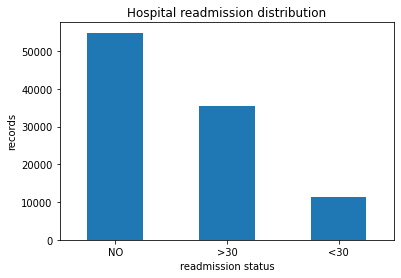

In [17]:
#visualization of the target variable
readmission_count = df['readmitted'].value_counts()
readmission_count.plot(kind='bar')
plt.title('Hospital readmission distribution')
plt.xlabel('readmission status')
plt.ylabel('records')
plt.xticks(rotation=0)
plt.show()

### We can see our dataset is imbalanced and most record belong to the group that was not readmitted within 30 days

In [18]:
df['age'].value_counts()

age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64

## checking readmission rate by age

In [19]:
''' checking readmission rate by age. making a new column for 30day readmission and finding the 
readmission percentage for each age group
'''

df['readmitted_30'] = (df['readmitted'] == '<30').astype(int)
age_readmission = df.groupby('age')['readmitted_30'].mean() * 100

print(age_readmission)

age
[0-10)       1.863354
[10-20)      5.788712
[20-30)     14.242607
[30-40)     11.231788
[40-50)     10.604027
[50-60)      9.666203
[60-70)     11.128408
[70-80)     11.773055
[80-90)     12.083503
[90-100)    11.099177
Name: readmitted_30, dtype: float64


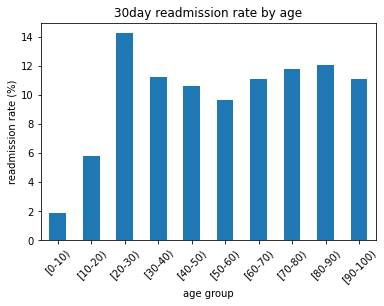

In [20]:
age_readmission.plot(kind='bar')
plt.title('30day readmission rate by age')
plt.xlabel('age group')
plt.ylabel('readmission rate (%)')
plt.xticks(rotation=45)
plt.show()

## exploring time spent in the hospital

In [21]:
df['time_in_hospital'].describe()

count    101766.000000
mean          4.395987
std           2.985108
min           1.000000
25%           2.000000
50%           4.000000
75%           6.000000
max          14.000000
Name: time_in_hospital, dtype: float64